To note, that the paper never states the exact word count for this figure but from the context, I assumed it was 4,843 words from the Glove emebdding from Fig. 4a (what this code uses). 
The code below finds the electrodes most correlated based on GPT 50 dimension embedding and for all those words that were also found in Glove. 

In [28]:
import numpy as np
import pandas as pd
import mne
import h5py
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from nilearn.plotting import plot_markers
from mne_bids import BIDSPath

from himalaya.backend import set_backend, get_backend
from himalaya.ridge import RidgeCV
from himalaya.scoring import correlation_score

from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import re
import mne
import numpy as np
from mne_bids import BIDSPath
from nilearn import datasets, image
from scipy.spatial import KDTree
from collections import Counter

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import gc

import matplotlib.pyplot as plt
from nilearn import plotting


In [2]:
transcript_path = "stimuli/podcast_transcript.csv"

df = pd.read_csv(transcript_path)
df.head(20)

,word,start,end
0,Act,3.710,3.790
1,"one,",3.990,4.190
2,monkey,4.651,4.931
3,in,4.951,5.011
4,the,5.051,5.111
5,middle.,5.151,5.391
6,So,6.592,6.732
7,there's,6.752,6.912
8,some,6.892,7.052
9,places,7.072,7.342


In [ ]:
glove_path = 'glove.6B.50d.txt'
#create the glove model based on our glove file in google drive
def load_glove_to_dict(file_path):
    glove_dict = {}
    print(f"Loading {file_path}...")

    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # Each line looks like: word 0.123 0.456 ...
            values = line.split()
            word = values[0]
            # Convert the numbers into a numpy array
            vector = np.asarray(values[1:], dtype='float32')
            glove_dict[word] = vector

    print(f"Done! {len(glove_dict)} words loaded.")
    return glove_dict


glove_model = load_glove_to_dict(glove_path)


def clean_word(w):
    """Better clean up: Lowercase + normalize apostrophes + strip punctuation."""
    w = str(w).lower()
    # Normalize curly apostrophes to straight ones for GloVe compatibility
    w = re.sub(r"[’‘’ʻ]", "'", w)
    # Strip punctuation but keep internal apostrophes (don't strip ')
    return w.strip(" .,!?;:\"()-[]")


df["word_clean"] = df["word"].apply(clean_word)


EXCLUDE_FILLERS = {'ch', 'hm', 'mhm', 'mm','uh', 'um'}

def get_glove_vector(w):
    if w in EXCLUDE_FILLERS or w not in glove_model:
        return None
    return glove_model[w]


df["glove_embedding"] = df["word_clean"].apply(get_glove_vector)

df_glove = df.dropna(subset=["glove_embedding"]).copy()

X_glove = np.stack(df_glove["glove_embedding"].values).astype("float32")

oov_count = len(df) - len(df_glove)

print("=" * 50)
print(f"Total words in transcript : {len(df)}")
print(f"Words WITH GloVe embedding: {len(df_glove)}")
print(f"Words WITHOUT (OOV/Fill)  : {oov_count}")
print(f"X_glove shape             : {X_glove.shape}")
print("=" * 50)

df_glove.head(8)

Loading glove.6B.50d.txt...
Done! 400000 words loaded.
Total words in transcript : 5136
Words WITH GloVe embedding: 4867
Words WITHOUT (OOV/Fill)  : 269
X_glove shape             : (4867, 50)


,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,in,4.951,5.011,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,the,5.051,5.111,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
5,middle.,5.151,5.391,middle,"[-0.15502, 1.0436, -0.22143, -0.89604, 0.49455..."
6,So,6.592,6.732,so,"[0.60308, -0.32024, 0.088857, -0.55176, 0.5318..."
8,some,6.892,7.052,some,"[0.92871, -0.10834, 0.21497, -0.50237, 0.10379..."


In [6]:

transcript_path = "stimuli/gpt2-xl/transcript.tsv"
df_gpt = pd.read_csv(transcript_path, sep="\t", index_col=0)


In [7]:
df_gpt.shape

(5491, 10)

In [8]:
embedding_path = "stimuli/gpt2-xl/features.hdf5"
modelname, layer = 'gpt2-xl', 48
with h5py.File(embedding_path, "r") as f:
    contextual_embeddings = f[f"layer-{layer}"][...]
print(f"LLM embedding matrix has shape: {contextual_embeddings.shape}")

LLM embedding matrix has shape: (5491, 1600)


In [9]:
#sanity check to ensure using last layer
import h5py
with h5py.File("stimuli/gpt2-xl/features.hdf5", "r") as f:
    print("Keys in file:", sorted(f.keys()))
    print("Min layer:", min(int(k.split('-')[1]) for k in f.keys() if k.startswith('layer')))
    print("Max layer:", max(int(k.split('-')[1]) for k in f.keys() if k.startswith('layer')))
    print("N layers:", len([k for k in f.keys() if k.startswith('layer')]))


Keys in file: ['layer-0', 'layer-1', 'layer-10', 'layer-11', 'layer-12', 'layer-13', 'layer-14', 'layer-15', 'layer-16', 'layer-17', 'layer-18', 'layer-19', 'layer-2', 'layer-20', 'layer-21', 'layer-22', 'layer-23', 'layer-24', 'layer-25', 'layer-26', 'layer-27', 'layer-28', 'layer-29', 'layer-3', 'layer-30', 'layer-31', 'layer-32', 'layer-33', 'layer-34', 'layer-35', 'layer-36', 'layer-37', 'layer-38', 'layer-39', 'layer-4', 'layer-40', 'layer-41', 'layer-42', 'layer-43', 'layer-44', 'layer-45', 'layer-46', 'layer-47', 'layer-48', 'layer-5', 'layer-6', 'layer-7', 'layer-8', 'layer-9']
Min layer: 0
Max layer: 48
N layers: 49


In [ ]:
# 1. PCA: Reduce from 1600 to 50 dimensions

pca = PCA(n_components=50)
embeddings_50d = pca.fit_transform(contextual_embeddings)
print(f"Reduced embedding shape: {embeddings_50d.shape}") # (5491, 50)

# 2. Group by word_idx and average the 50-d embeddings

aligned_embeddings_50d = []
for _, group in df_gpt.groupby("word_idx"):
    indices = group.index.to_numpy()
    average_emb = embeddings_50d[indices].mean(0) 
    aligned_embeddings_50d.append(average_emb)

aligned_embeddings_50d = np.stack(aligned_embeddings_50d)
print(f"Final word-level embedding matrix shape: {aligned_embeddings_50d.shape}") # (5136, 50)

# 3. Create a word-level DataFrame

df_words = df_gpt.groupby("word_idx").first().reset_index()

# 4. Insert the 50-d embeddings into the new DataFrame
df_words["gpt_embedding_50d"] = list(aligned_embeddings_50d)

print(f"df_words shape: {df_words.shape}")
df_words.head()

Reduced embedding shape: (5491, 50)
Final word-level embedding matrix shape: (5136, 50)
df_words shape: (5136, 11)


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.968685, -2.7204404, -2.0838842, -4.468625,..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.2787919, -0.8526732, -2.1737404, 0.6747831..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.1525632, 1.3146999, -3.9557092, 1.93419, 5..."
3,3,in,4.951,5.011,Ġin,287,15,0.004237,0,4.444838,"[-6.756082, 2.8779151, 4.293614, -1.2894516, 1..."
4,4,the,5.051,5.111,Ġthe,262,0,0.392205,262,3.781622,"[-6.8897104, 5.5559196, -1.2473552, 5.097347, ..."


In [ ]:
# Apply cleaning
df_words["word_clean"] = df_words["word"].apply(clean_word)

#Exclude fillers 
mask = df_words["word_clean"].apply(
    lambda w: w not in EXCLUDE_FILLERS and w in glove_model
)

# Apply the mask to create your final filtered dataframe
df_gpt_final = df_words[mask].copy()


# Verification
print(f"Initial Word-Level rows : {len(df_words)}")
print(f"Final aligned rows      : {len(df_gpt_final)}")
print(f"Rows dropped            : {len(df_words) - len(df_gpt_final)}")

df_gpt_final.head(3)

Initial Word-Level rows : 5136
Final aligned rows      : 4867
Rows dropped            : 269


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d,word_clean
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.968685, -2.7204404, -2.0838842, -4.468625,...",act
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.2787919, -0.8526732, -2.1737404, 0.6747831...",one
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.1525632, 1.3146999, -3.9557092, 1.93419, 5...",monkey


In [14]:
gpt_glove_embedding = np.stack(df_gpt_final['gpt_embedding_50d'].values).astype("float32")
gpt_glove_embedding.shape

(4867, 50)

In [ ]:
#Now that we have all embeddings for the last layer (layer 48) and we have PCA's it into 50 dimeniosns
#and the it only has the words that were also found in the glove embedding
#we can do our verisioon of stastical testing: for all patients:
#### 1)Run encoding model for all electrodes in left hemsipehre
#### 2)caluclate the correlation with the brain activity and store it
##At the end calculate which electrodes were most signficant given all of these correlation values 

#doing k folds of 10

In [ ]:
bids_root = "/Users/iadician/Desktop/AI NEURO CODE/"

Processing sub-09
  GPT-2 embedding shape: (4867, 50)
  LH electrodes: 188


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1358/729269875.py:48: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


  Epochs kept: 4861 / 4867
  epochs_data shape: (4861, 188, 2049)  (14.98 GB)
  epochs_windowed: (4861, 188, 161)  (0.59 GB)
  X: (4861, 50)  Y: (4861, 30268)  Y size: 0.59 GB
    fold 1/10...
    fold 2/10...
    fold 3/10...
    fold 4/10...
    fold 5/10...
    fold 6/10...
    fold 7/10...
    fold 8/10...
    fold 9/10...
    fold 10/10...
  Correlations shape: (10, 188, 161)
  Saved: figure_6a_results/corrs_gpt2_sub09.npy
  Saved: figure_6a_results/electrodes_gpt2_sub09.csv


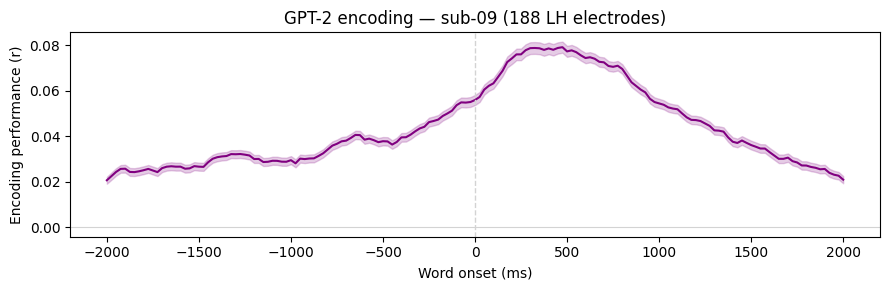


✓ sub-09 done. Change subj_id and re-run for next subject.


In [ ]:


RESULTS_DIR = "figure_6a_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ── CHANGE THIS EACH RUN ───────────────────────────────────────────────────────
subj_id = "09"   # "02", "03", "04", "05", "06", "07", "08", "09"
# ──────────────────────────────────────────────────────────────────────────────

print(f"Processing sub-{subj_id}")


save_corrs = f"{RESULTS_DIR}/corrs_gpt2_sub{subj_id}.npy"
save_elec  = f"{RESULTS_DIR}/electrodes_gpt2_sub{subj_id}.csv"
if os.path.exists(save_corrs) and os.path.exists(save_elec):
    print(f"  Already exists — delete files to rerun")
else:

    # Encoding setup 
    alphas   = np.logspace(1, 10, 10)
    inner_cv = KFold(n_splits=5, shuffle=False)
    model    = make_pipeline(
        StandardScaler(),
        RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
    )

    # Load GPT-2 embeddings 
    X_gpt2 = gpt_glove_embedding
    print(f"  GPT-2 embedding shape: {X_gpt2.shape}")

    # Load raw, LH only 
    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=subj_id, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

    ch2loc    = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask   = coords_mm[:, 0] < 0
    raw       = raw.copy().pick([ch for ch, k in zip(raw.ch_names, lh_mask) if k])
    print(f"  LH electrodes: {len(raw.ch_names)}")

    # Epochs 
    sfreq  = raw.info['sfreq']
    events = np.zeros((len(df_glove), 3), dtype=int)
    events[:, 0] = (df_glove['start'].values * sfreq).astype(int)

    epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                        baseline=None, proj=False, event_id=None,
                        preload=True, event_repeated="merge", verbose=False)
    print(f"  Epochs kept: {len(epochs)} / {len(df_glove)}")

    # Free raw from memory immediately — no longer needed
    del raw
    gc.collect()

    # Window averaging
    times           = epochs.times
    lag_centers_sec = np.arange(-2.0, 2.0 + 0.025/2, 0.025)
    WIN_HALF        = 0.100
    lag_masks       = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                       for τ in lag_centers_sec]

    epochs_data         = epochs.get_data(copy=True)
    n_words, n_elec, _  = epochs_data.shape
    epochs_shape        = (n_elec, 161)

    print(f"  epochs_data shape: {epochs_data.shape}  "
          f"({epochs_data.nbytes / 1e9:.2f} GB)")

    epochs_windowed = np.stack(
        [epochs_data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
    ).astype(np.float32)

    # Free full-resolution epochs immediately
    del epochs_data, epochs.preload
    gc.collect()

    print(f"  epochs_windowed: {epochs_windowed.shape}  "
          f"({epochs_windowed.nbytes / 1e9:.2f} GB)")

    # Align embeddings 
    sel = epochs.selection
    X   = X_gpt2[sel].astype(np.float32)
    Y   = epochs_windowed.reshape(n_words, n_elec * 161).astype(np.float32)

    del epochs_windowed
    gc.collect()

    print(f"  X: {X.shape}  Y: {Y.shape}  "
          f"Y size: {Y.nbytes / 1e9:.2f} GB")

    # Train encoding model
    def train_encoding(X, Y):
        corrs = []
        kfold = KFold(10, shuffle=False)
        for fold, (train_idx, test_idx) in enumerate(kfold.split(X)):
            print(f"    fold {fold+1}/10...")
            X_train, X_test = X[train_idx], X[test_idx]
            Y_train, Y_test = Y[train_idx], Y[test_idx]
            scaler  = StandardScaler()
            Y_train = scaler.fit_transform(Y_train)
            Y_test  = scaler.transform(Y_test)
            model.fit(X_train, Y_train)
            Y_preds = model.predict(X_test)
            corr    = correlation_score(Y_test, Y_preds).reshape(epochs_shape)
            if "torch" in get_backend().__name__:
                corr = corr.numpy(force=True)
            corrs.append(corr)
            gc.collect()
        return np.stack(corrs)

    corrs_gpt2 = train_encoding(X, Y)
    print(f"  Correlations shape: {corrs_gpt2.shape}")

    del X, Y
    gc.collect()

    # Save
    np.save(save_corrs, corrs_gpt2)

    raw2    = mne.io.read_raw_fif(file_path.fpath, verbose=False, preload=False)
    ch2loc2 = {ch['ch_name']: ch['loc'][:3] for ch in raw2.info['chs']}
    coords2 = np.vstack([ch2loc2[ch] for ch in raw2.ch_names]) * 1000
    lh2     = coords2[:, 0] < 0
    lh_names = [ch for ch, k in zip(raw2.ch_names, lh2) if k]
    lh_coords = coords2[lh2]
    elec_df = pd.DataFrame({
        "subject": subj_id,
        "ch_name": lh_names,
        "x_mni":   lh_coords[:, 0],
        "y_mni":   lh_coords[:, 1],
        "z_mni":   lh_coords[:, 2],
    })
    elec_df.to_csv(save_elec, index=False)
    assert len(elec_df) == corrs_gpt2.shape[1], "MISMATCH"
    print(f"  Saved: {save_corrs}")
    print(f"  Saved: {save_elec}")

    # Quick plot
    lags_ms = np.linspace(-2000, 2000, 161)
    mean_s  = corrs_gpt2.mean((0, 1))
    err_s   = corrs_gpt2.std((0, 1)) / np.sqrt(np.prod(corrs_gpt2.shape[:2]))
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(lags_ms, mean_s, color='purple', lw=1.5)
    ax.fill_between(lags_ms, mean_s - err_s, mean_s + err_s, alpha=0.2, color='purple')
    ax.axvline(0, color='lightgray', ls='--', lw=1)
    ax.axhline(0, color='lightgray', ls='-',  lw=0.8)
    ax.set_xlabel("Word onset (ms)")
    ax.set_ylabel("Encoding performance (r)")
    ax.set_title(f"GPT-2 encoding — sub-{subj_id} ({n_elec} LH electrodes)")
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/encoding_sub{subj_id}.png", dpi=150, bbox_inches='tight')
    plt.show()

    del corrs_gpt2
    gc.collect()
    print(f"\n✓ sub-{subj_id} done. Change subj_id and re-run for next subject.")

sub-02: 0 / 90 electrodes significant
sub-03: 53 / 191 electrodes significant
sub-04: 19 / 77 electrodes significant
sub-05: 4 / 157 electrodes significant
sub-06: 22 / 166 electrodes significant
sub-07: 11 / 116 electrodes significant
sub-08: 19 / 72 electrodes significant
sub-09: 78 / 188 electrodes significant

Total significant GPT-2 electrodes: 206


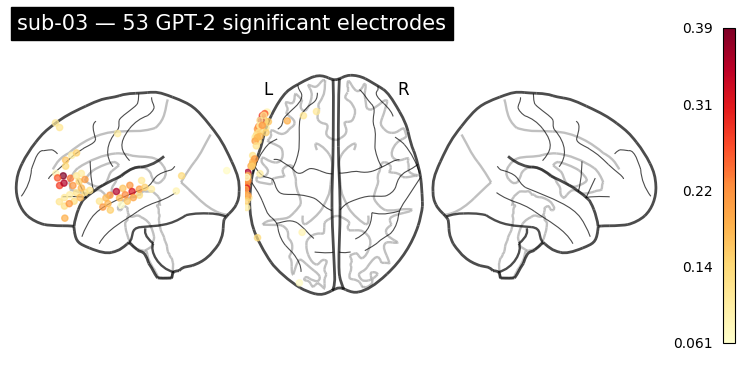

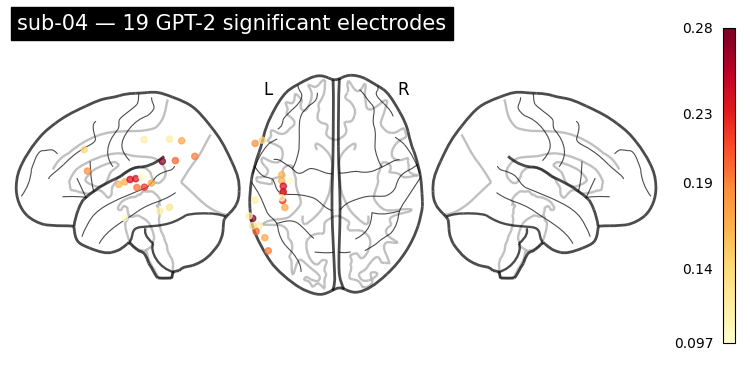

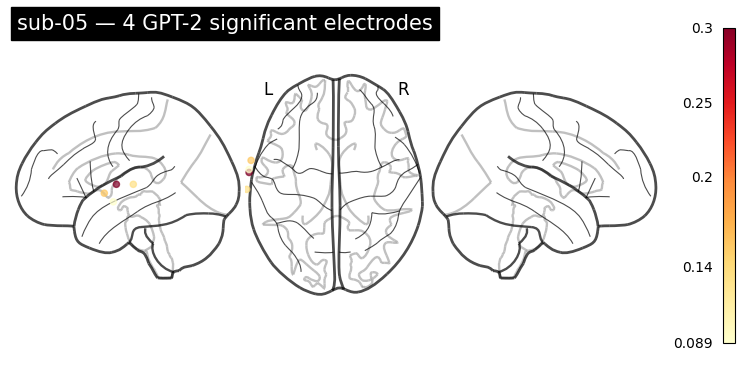

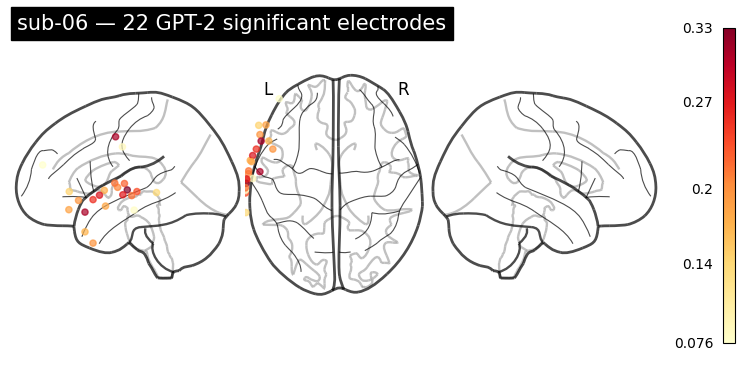

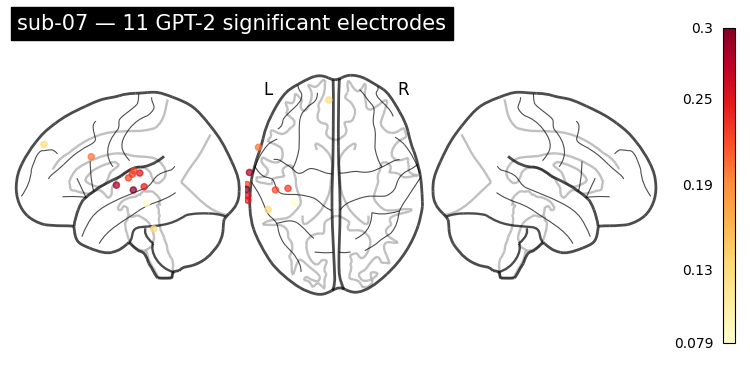

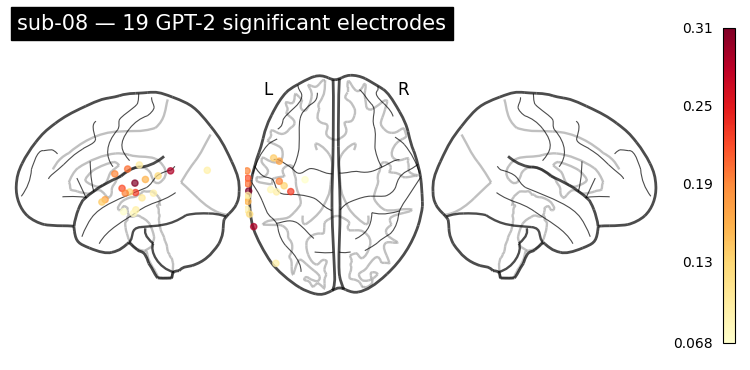

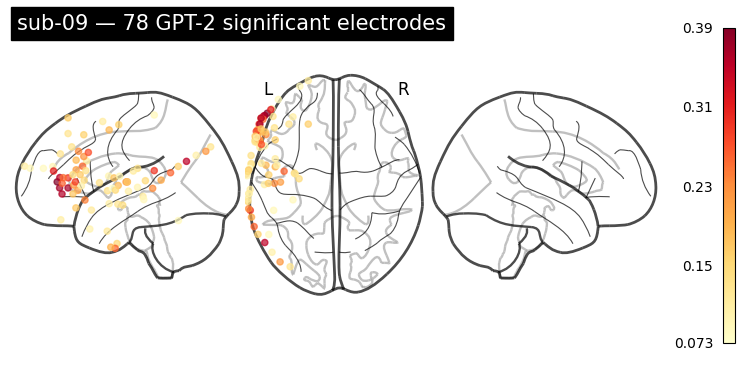

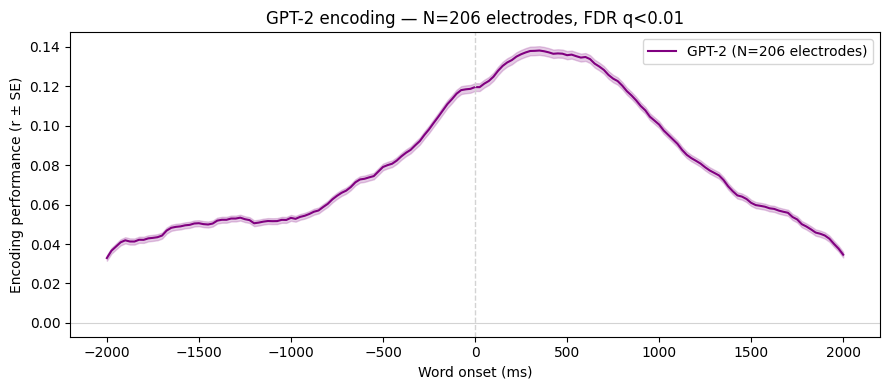


Peak r range: [0.061, 0.393]


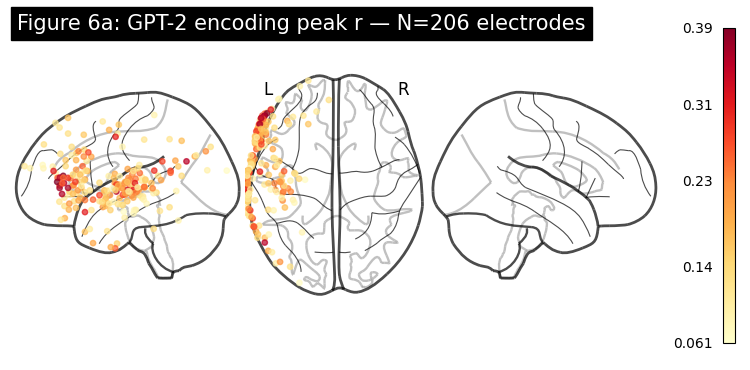

In [18]:
################# SIGNIFICANCE TESTING ############
##This was the same method done fro glove, takes the average for all lags
## also tested the other two alternatives we are the average from 0-500 ms window, and the maximum correlation, to see what would be found
##### Results: thsi is the best method 


#re-loading saved correlations, so this cell can run independently
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms       = np.linspace(-2000, 2000, 161)
all_sig_corrs = []
all_sig_elec  = []

for sid in subject_ids:
    try:
        corrs   = np.load(f"figure_6a_results/corrs_gpt2_sub{sid}.npy")
        elec_df = pd.read_csv(f"figure_6a_results/electrodes_gpt2_sub{sid}.csv")
    except FileNotFoundError:
        print(f"sub-{sid}: missing file, skipping")
        continue

    assert corrs.shape[1] == len(elec_df)

    overall_per_fold    = corrs.mean(axis=2)           # (n_folds, n_elec)
    t_stats, p_vals     = stats.ttest_1samp(overall_per_fold, popmean=0, axis=0)
    p_vals              = p_vals / 2                   # one-tailed
    p_vals[t_stats < 0] = 1.0
    sig_mask, _         = fdrcorrection(p_vals, alpha=0.01, method='indep')

    n_sig = sig_mask.sum()
    print(f"sub-{sid}: {n_sig} / {len(sig_mask)} electrodes significant")

    if n_sig > 0:
        all_sig_corrs.append(corrs[:, sig_mask, :])
        sig_rows = elec_df[sig_mask].copy()
        sig_rows["elec_idx"] = np.where(sig_mask)[0]
        all_sig_elec.append(sig_rows)

        # Per-subject brain plot
        coords_sub = sig_rows[["x_mni", "y_mni", "z_mni"]].values
        peak_corrs = corrs[:, sig_mask, :].mean(axis=0).max(axis=1)  # (n_sig,)
        plot_markers(peak_corrs, coords_sub,
                     node_size=20, display_mode='lzr',
                     node_cmap='YlOrRd',
                     node_vmin=peak_corrs.min(),
                     node_vmax=peak_corrs.max(),
                     colorbar=True,
                     title=f"sub-{sid} — {n_sig} GPT-2 significant electrodes")

# Save master CSV 
sig_elec_master = pd.concat(all_sig_elec, ignore_index=True)
sig_elec_master.to_csv("figure_6a_results/significant_electrodes_gpt2.csv", index=False)
print(f"\nTotal significant GPT-2 electrodes: {len(sig_elec_master)}")

# All-subject encoding curve 
all_pooled  = np.concatenate(all_sig_corrs, axis=1)
n_sig_total = all_pooled.shape[1]
mean_all    = all_pooled.mean((0, 1))
err_all     = all_pooled.std((0, 1)) / np.sqrt(all_pooled.shape[0] * all_pooled.shape[1])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lags_ms, mean_all, color='purple', lw=1.5,
        label=f'GPT-2 (N={n_sig_total} electrodes)')
ax.fill_between(lags_ms, mean_all - err_all, mean_all + err_all, alpha=0.2, color='purple')
ax.axvline(0, color='lightgray', ls='--', lw=1)
ax.axhline(0, color='lightgray', ls='-',  lw=0.8)
ax.set_xlabel("Word onset (ms)")
ax.set_ylabel("Encoding performance (r ± SE)")
ax.set_title(f"GPT-2 encoding — N={n_sig_total} electrodes, FDR q<0.01")
ax.legend()
plt.tight_layout()
plt.savefig("figure_6a_results/fig6a_encoding_curve.png", dpi=150, bbox_inches='tight')
plt.show()

# Figure 6a brain map: with all selected electrodes
all_coords     = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

# Peak encoding r per electrode: mean across folds, then max across lags
all_corrs_cat  = np.concatenate(all_sig_corrs, axis=1)  # (n_folds, N, 161)
peak_per_elec  = all_corrs_cat.mean(axis=0).max(axis=1) # (N,) — peak lag per electrode

print(f"\nPeak r range: [{peak_per_elec.min():.3f}, {peak_per_elec.max():.3f}]")

plot_markers(peak_per_elec, all_coords,
             node_size=15,
             display_mode='lzr',
             node_cmap='YlOrRd',
             node_vmin=peak_per_elec.min(),
             node_vmax=peak_per_elec.max(),
             colorbar=True,
             title=f"Figure 6a: GPT-2 encoding peak r — N={n_sig_total} electrodes")

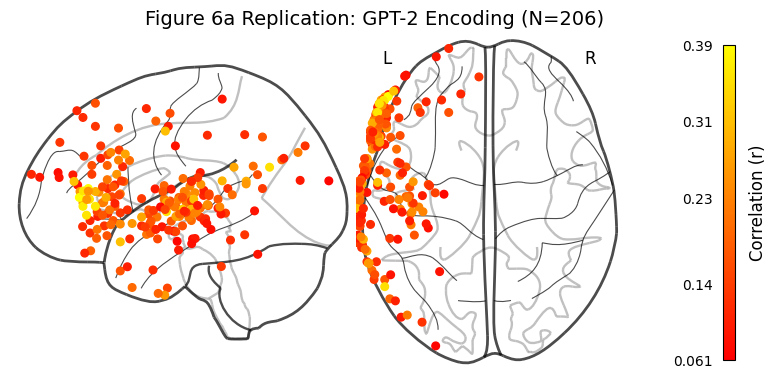

In [34]:
#Main 2 figure plots

#plot 1:

# re-loading all the saved correlation values
all_coords = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values
all_corrs_cat = np.concatenate(all_sig_corrs, axis=1)  
peak_per_elec = all_corrs_cat.mean(axis=0).max(axis=1) 

v_min, v_max = peak_per_elec.min(), peak_per_elec.max()

# Plotting
display = plotting.plot_markers(
    peak_per_elec, 
    all_coords,
    node_size=30,
    display_mode='lzr',
    node_cmap='autumn',
    node_vmin=v_min,
    node_vmax=v_max,
    colorbar=True,
    alpha=1.0
)

# Remove the Right Hemisphere subplot
display.axes['r'].ax.remove()
del display.axes['r']

if display._cbar is not None:
    display._cbar.set_label('Correlation (r)', fontsize=12, labelpad=10)

plt.gcf().suptitle(
    f"Figure 6a Replication: GPT-2 Encoding (N={len(sig_elec_master)})", 
    fontsize=14, 
    y=1.05 
)

# Save and show
plt.savefig("figure_6a_autumn_left_top.png", dpi=300, bbox_inches='tight')
plt.show()

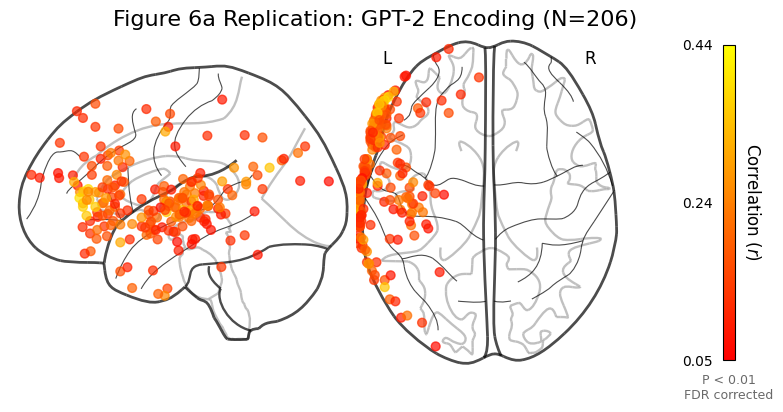

Saved with range 0.05 to 0.44.


In [35]:

#Plot 2

mean_per_elec = all_pooled.mean(axis=0)   
peak_corr     = mean_per_elec.max(axis=1) 
coords        = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

# Color Calibration ( range: 0.05 to 0.44)
vmin = 0.05  
vmax = 0.44  
mid  = (vmin + vmax) / 2 # 0.245

cmap = plt.cm.autumn # Red (low) → Yellow (high)

# 3. Plotting
display = plotting.plot_markers(
    node_values  = peak_corr,
    node_coords  = coords,
    node_size    = 40,            
    node_cmap    = cmap,
    node_vmin    = vmin,
    node_vmax    = vmax,          
    display_mode = "lzr",
    colorbar     = True,
)

# Remove the Right Hemisphere View
display.axes['r'].ax.remove()
del display.axes['r']

plt.gcf().suptitle(
    f"Figure 6a Replication: GPT-2 Encoding (N={len(sig_elec_master)})", 
    fontsize=16, y=1.05
)


fig     = plt.gcf()
cbar_ax = fig.axes[-1]


cbar_ax.set_yticks([vmin, mid, vmax])
cbar_ax.set_yticklabels([f"{vmin:.2f}", f"{mid:.2f}", f"{vmax:.2f}"], fontsize=10)
cbar_ax.set_ylabel("Correlation ($r$)", fontsize=12, rotation=270, labelpad=20)


cbar_pos = cbar_ax.get_position()
fig.text(
    cbar_pos.x0 + cbar_pos.width / 2,
    cbar_pos.y0 - 0.04,
    "P < 0.01\nFDR corrected",
    ha="center", va="top", fontsize=9, color="dimgrey",
    transform=fig.transFigure,
)


plt.savefig("figure_6_A_HighRes.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved with range {vmin} to {vmax}.")


Peak r range: [0.061, 0.393]


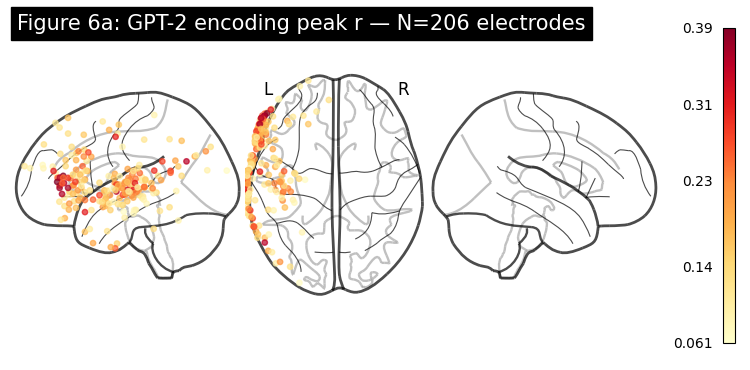

In [5]:
all_coords     = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

# Peak encoding r per electrode: mean across folds, then max across lags
all_corrs_cat  = np.concatenate(all_sig_corrs, axis=1)  # (n_folds, N, 161)
peak_per_elec  = all_corrs_cat.mean(axis=0).max(axis=1) # (N,) — peak lag per electrode

print(f"\nPeak r range: [{peak_per_elec.min():.3f}, {peak_per_elec.max():.3f}]")

plot_markers(peak_per_elec, all_coords,
             node_size=15,
             display_mode='lzr',
             node_cmap='YlOrRd',
             node_vmin=peak_per_elec.min(),
             node_vmax=peak_per_elec.max(),
             colorbar=True,
             title=f"Figure 6a: GPT-2 encoding peak r — N={n_sig_total} electrodes")

# Other Methods tested (not the final ones used)

In [ ]:
#THIS IS THE OTHER METHOD WE TESTED BUT DIDN'T DO, WHICH WAS average lag across specific time window 0-500
subject_ids   = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms       = np.linspace(-2000, 2000, 161)
window_mask   = (lags_ms >= 0) & (lags_ms <= 500)
all_sig_corrs = []
all_sig_elec  = []

for sid in subject_ids:
    try:
        corrs   = np.load(f"figure_6a_results/corrs_gpt2_sub{sid}.npy")
        elec_df = pd.read_csv(f"figure_6a_results/electrodes_gpt2_sub{sid}.csv")
    except FileNotFoundError:
        print(f"sub-{sid}: missing file, skipping")
        continue

    assert corrs.shape[1] == len(elec_df)

    # Average only within 0–500ms window
    window_per_fold     = corrs[:, :, window_mask].mean(axis=2)  # (n_folds, n_elec)
    t_stats, p_vals     = stats.ttest_1samp(window_per_fold, popmean=0, axis=0)
    p_vals              = p_vals / 2
    p_vals[t_stats < 0] = 1.0
    sig_mask, _         = fdrcorrection(p_vals, alpha=0.01, method='indep')

    n_sig = sig_mask.sum()
    print(f"sub-{sid}: {n_sig} / {len(sig_mask)} electrodes significant (0–500ms window)")

    if n_sig > 0:
        all_sig_corrs.append(corrs[:, sig_mask, :])
        sig_rows = elec_df[sig_mask].copy()
        sig_rows["elec_idx"] = np.where(sig_mask)[0]
        all_sig_elec.append(sig_rows)

sig_elec_master = pd.concat(all_sig_elec, ignore_index=True)
sig_elec_master.to_csv("figure_6a_results/significant_electrodes_gpt2_window.csv", index=False)
print(f"\nTotal (0–500ms window): {len(sig_elec_master)}")

sub-02: 1 / 90 electrodes significant (0–500ms window)
sub-03: 63 / 191 electrodes significant (0–500ms window)
sub-04: 21 / 77 electrodes significant (0–500ms window)
sub-05: 8 / 157 electrodes significant (0–500ms window)
sub-06: 53 / 166 electrodes significant (0–500ms window)
sub-07: 17 / 116 electrodes significant (0–500ms window)
sub-08: 16 / 72 electrodes significant (0–500ms window)
sub-09: 87 / 188 electrodes significant (0–500ms window)

Total (0–500ms window): 266


In [ ]:
#THIS IS THE OTHER METHOD WE TESTED BUT DIDN'T DO WHICH IS PEAK CORRELATION ACROSS lags
subject_ids   = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms       = np.linspace(-2000, 2000, 161)
all_sig_corrs = []
all_sig_elec  = []

for sid in subject_ids:
    try:
        corrs   = np.load(f"figure_6a_results/corrs_gpt2_sub{sid}.npy")
        elec_df = pd.read_csv(f"figure_6a_results/electrodes_gpt2_sub{sid}.csv")
    except FileNotFoundError:
        print(f"sub-{sid}: missing file, skipping")
        continue

    assert corrs.shape[1] == len(elec_df)

    # Take max across lags (peak encoding performance per fold per electrode)
    peak_per_fold       = corrs.max(axis=2)            # (n_folds, n_elec)
    t_stats, p_vals     = stats.ttest_1samp(peak_per_fold, popmean=0, axis=0)
    p_vals              = p_vals / 2
    p_vals[t_stats < 0] = 1.0
    sig_mask, _         = fdrcorrection(p_vals, alpha=0.01, method='indep')

    n_sig = sig_mask.sum()
    print(f"sub-{sid}: {n_sig} / {len(sig_mask)} electrodes significant (peak)")

    if n_sig > 0:
        all_sig_corrs.append(corrs[:, sig_mask, :])
        sig_rows = elec_df[sig_mask].copy()
        sig_rows["elec_idx"] = np.where(sig_mask)[0]
        all_sig_elec.append(sig_rows)

sig_elec_master = pd.concat(all_sig_elec, ignore_index=True)
sig_elec_master.to_csv("figure_6a_results/significant_electrodes_gpt2_peak.csv", index=False)
print(f"\nTotal (peak): {len(sig_elec_master)}")

sub-02: 84 / 90 electrodes significant (peak)
sub-03: 191 / 191 electrodes significant (peak)
sub-04: 76 / 77 electrodes significant (peak)
sub-05: 157 / 157 electrodes significant (peak)
sub-06: 166 / 166 electrodes significant (peak)
sub-07: 65 / 116 electrodes significant (peak)
sub-08: 72 / 72 electrodes significant (peak)
sub-09: 186 / 188 electrodes significant (peak)

Total (peak): 997
